## Расстояние Левенштейна


импорты

In [1]:
from itertools import groupby

import pandas as pd
from rapidfuzz import fuzz
import matplotlib.pyplot as plt
import scipy.stats as st
import pyarrow.parquet as pq

**загрузка данных**

In [2]:
matches = pd.read_parquet('data/matches.parquet')
items_human = pd.read_parquet('data/items_human.parquet')
matches['target'] = matches['target'].astype(int)

**составим таблицу pairs с колонками id1 id2 target name1 category1 name2 category2**

In [3]:
items1 = items_human[['id', 'name', 'category']].rename(columns = {'id' : 'id1', 'name' : 'name1', 'category' : 'category1'})
items2 = items_human[['id', 'name', 'category']].rename(columns = {'id' : 'id2', 'name' : 'name2', 'category' : 'category2'})

pairs = matches.merge(items1, on='id1', how='left')
pairs = pairs.merge(items2, on='id2', how='left')


In [4]:
print(pairs.head())
print(pairs.shape)
print(pairs['name1'].isna().sum())

   id1           id2  target  \
0   32  188978721454       0   
1   34  197568543106       0   
2   37  661425040668       0   
3   97  274877917548       0   
4  154  283467899529       0   

                                               name1          category1  \
0  очки с футляром-змейка fedrov мод. 1047 цвет 3...             Аптека   
1  зубная щетка r.o.c.s. black edition classic, ч...  Красота и гигиена   
2                                  сандалии fre gamo              Обувь   
3  acuvue астигматические линзы oasys for astigma...             Аптека   
4                      дворцовый пуэр (5 лет), 500 г   Продукты питания   

                                               name2          category2  
0  фотохромные очки с футляром-змейка fedrov мод....             Аптека  
1  зубная щетка r.o.c.s. red edition classic, сре...  Красота и гигиена  
2                                fre gamo / сандалии              Обувь  
3  acuvue / контактные линзы acuvue oasys for ast...        

In [5]:
print((pairs['category1'] != pairs['category2']).sum())

0


сравниваются товары только из одной категории

Отличается ли доля дублей по категориям?

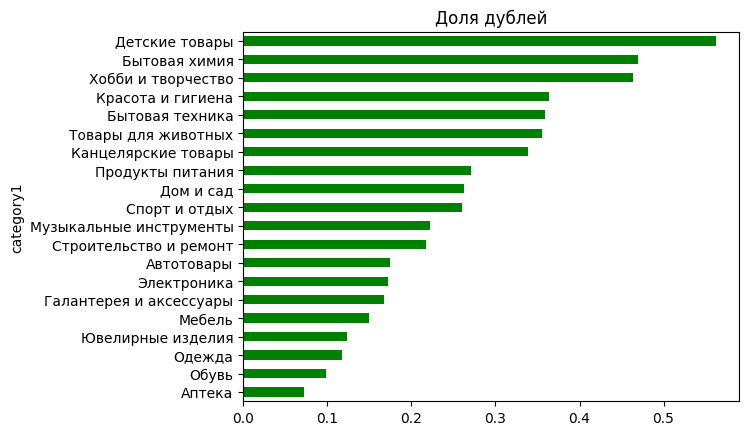

In [6]:
category = pairs.groupby('category1')['target'].mean().sort_values()
plt.title('Доля дублей')
category.plot.barh(color='green')
plt.show()




In [7]:
print(fuzz.ratio(pairs['name1'].loc[0], pairs['name2'].loc[0]))

78.30188679245282


In [8]:
distance = [fuzz.ratio(name1, name2) for name1, name2 in zip(pairs['name1'], pairs['name2'])]
pairs['sim_name'] = distance


In [9]:
pairs['sim_name'].describe()

count    365654.000000
mean         57.377947
std          20.071255
min           0.000000
25%          42.553191
50%          56.000000
75%          72.463768
max         100.000000
Name: sim_name, dtype: float64

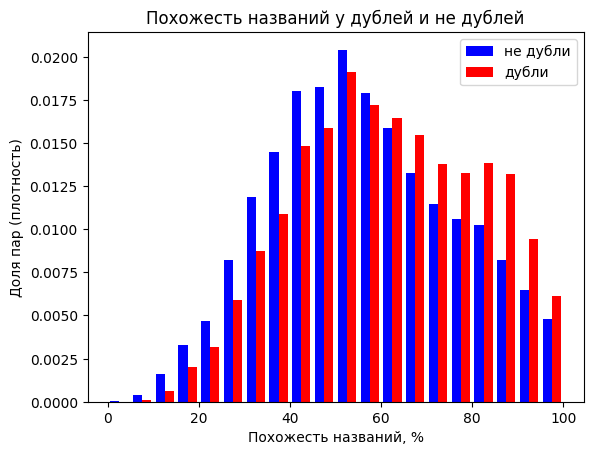

In [10]:
sim_name_target0 = pairs[pairs['target'] == 0]['sim_name']
sim_name_target1 = pairs[pairs['target'] == 1]['sim_name']
plt.hist([sim_name_target0, sim_name_target1], bins=20, density=True,
         label=['не дубли', 'дубли'], color=['blue', 'red'])
plt.xlabel('Похожесть названий, %')
plt.ylabel('Доля пар (плотность)')
plt.title('Похожесть названий у дублей и не дублей')
plt.legend()
plt.show()

Дубли в среднем имеют более похожие названия: при похожести выше 60% они встречаются относительно чаще, чем не дубли, а ниже 60% - реже. Но при любом значении похожести есть и дубли, и не дубли

### **Гипотеза:** у пар с длинными названиями высокая похожесть надёжнее указывает на дубль, чем у пар с короткими
<br> добавим колонку в таблицу минимальная длина из двух названий

In [11]:
pairs['len1'] = pairs['name1'].str.len()
pairs['len2'] = pairs['name2'].str.len()
pairs['min_len'] = pairs[['len1', 'len2']].min(axis=1)
print(pairs.head())

   id1           id2  target  \
0   32  188978721454       0   
1   34  197568543106       0   
2   37  661425040668       0   
3   97  274877917548       0   
4  154  283467899529       0   

                                               name1          category1  \
0  очки с футляром-змейка fedrov мод. 1047 цвет 3...             Аптека   
1  зубная щетка r.o.c.s. black edition classic, ч...  Красота и гигиена   
2                                  сандалии fre gamo              Обувь   
3  acuvue астигматические линзы oasys for astigma...             Аптека   
4                      дворцовый пуэр (5 лет), 500 г   Продукты питания   

                                               name2          category2  \
0  фотохромные очки с футляром-змейка fedrov мод....             Аптека   
1  зубная щетка r.o.c.s. red edition classic, сре...  Красота и гигиена   
2                                fre gamo / сандалии              Обувь   
3  acuvue / контактные линзы acuvue oasys for ast...    

In [12]:
pairs['len_group'] = pd.qcut(pairs['min_len'], 3, labels=['короткие', 'средние', 'длинные'])

In [13]:
groupby_len_name = pairs.groupby('len_group', observed=True)
print(groupby_len_name['min_len'].agg(['min', 'max']))

           min  max
len_group          
короткие     1   36
средние     37   55
длинные     56  251


In [14]:
print(groupby_len_name['target'].mean())

len_group
короткие    0.225598
средние     0.299592
длинные     0.244791
Name: target, dtype: float64


In [15]:
print(groupby_len_name['sim_name'].mean())н

SyntaxError: invalid syntax (3591113825.py, line 1)

In [17]:
pairs_sim90 = pairs[pairs['sim_name'] > 90]
groupby_len_name90 = pairs_sim90.groupby('len_group', observed=True)
print(groupby_len_name90.size())

len_group
короткие     4873
средние      4549
длинные     12896
dtype: int64


In [18]:
print(groupby_len_name90['target'].mean())

len_group
короткие    0.182639
средние     0.529787
длинные     0.303738
Name: target, dtype: float64


## Вывод:<br>
**по похожести названий отделить дубли от не дублей нельзя**